   ResponseId                      MainBranch              Age  \
0           1  I am a developer by profession  25-34 years old   
1           2  I am a developer by profession  25-34 years old   
2           3  I am a developer by profession  35-44 years old   
3           4  I am a developer by profession  35-44 years old   
4           5  I am a developer by profession  35-44 years old   

                                           EdLevel  \
0  Master’s degree (M.A., M.S., M.Eng., MBA, etc.)   
1              Associate degree (A.A., A.S., etc.)   
2     Bachelor’s degree (B.A., B.S., B.Eng., etc.)   
3     Bachelor’s degree (B.A., B.S., B.Eng., etc.)   
4  Master’s degree (M.A., M.S., M.Eng., MBA, etc.)   

                                          Employment  \
0                                           Employed   
1                                           Employed   
2  Independent contractor, freelancer, or self-em...   
3                                           Employed  

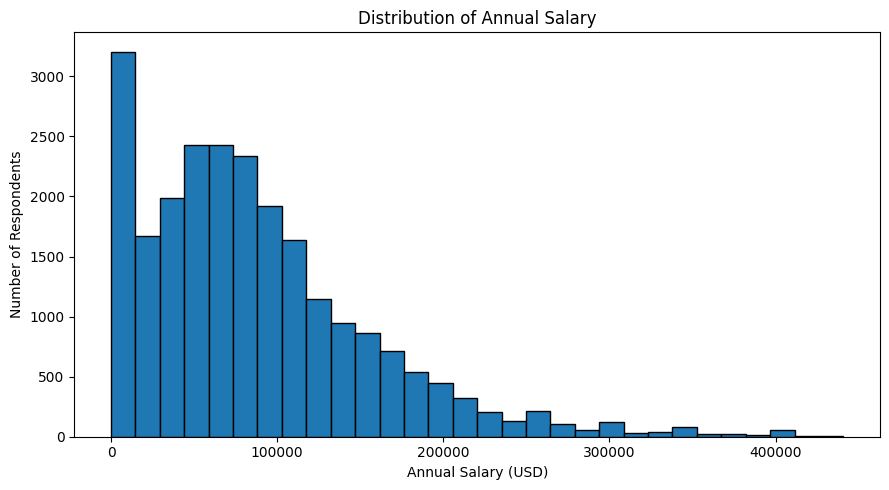

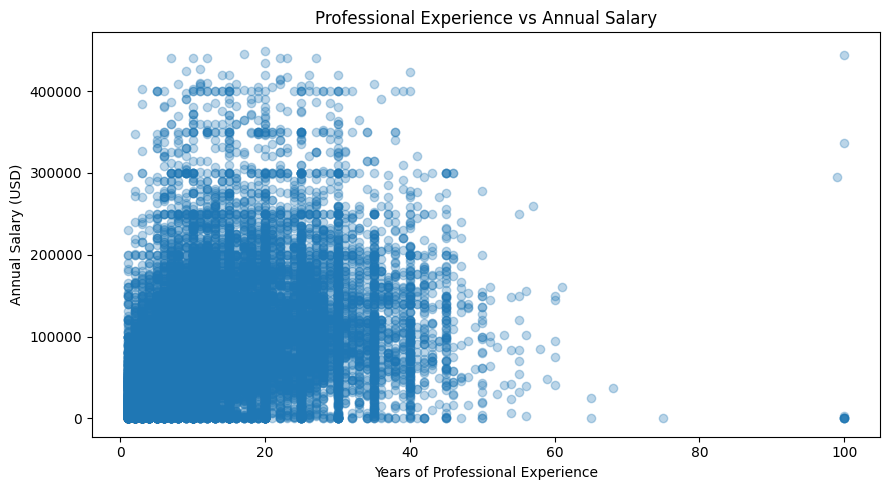

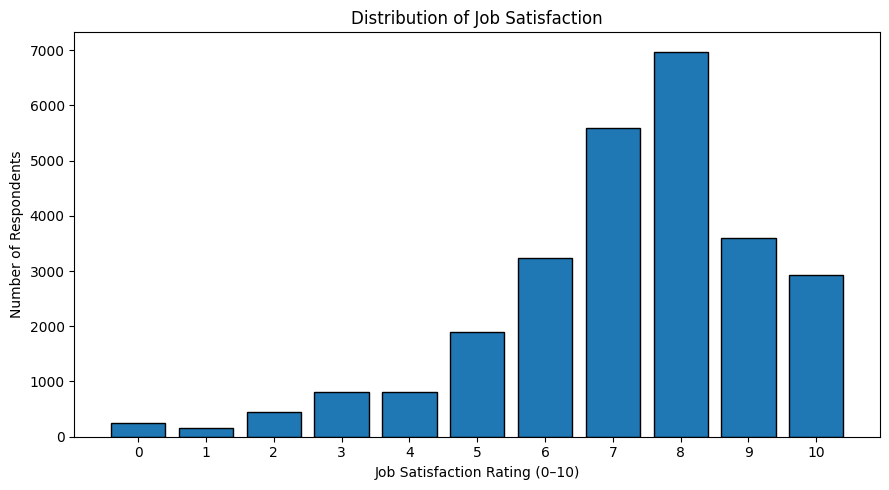

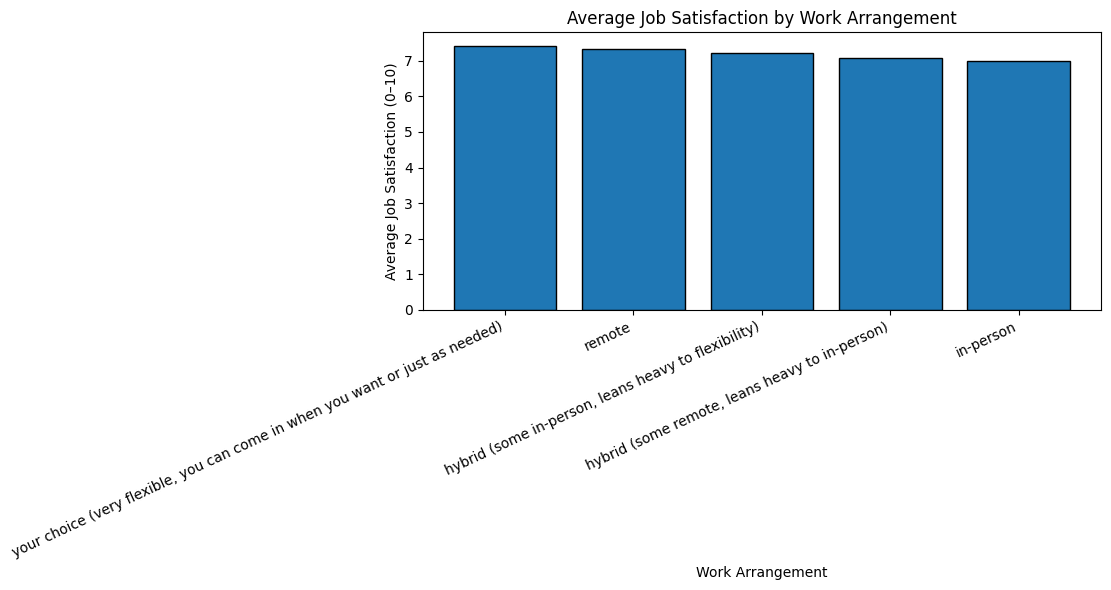

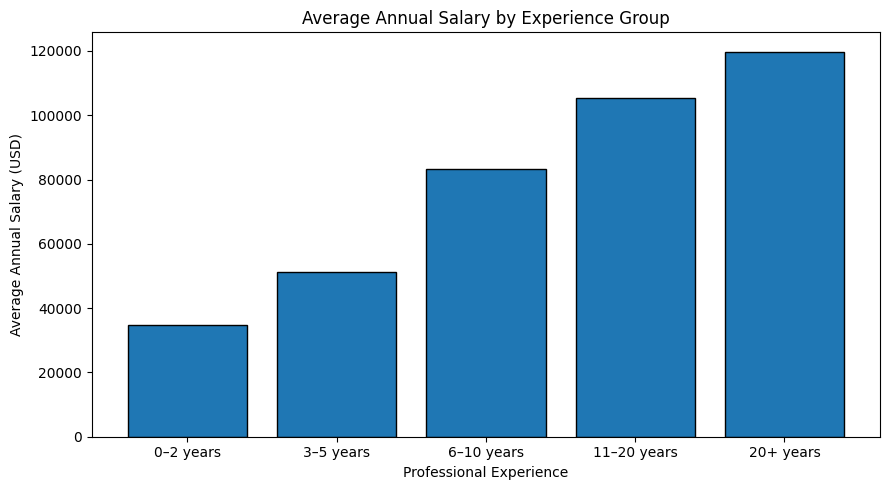

In [10]:
# step 1: load data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# Added low_memory=False to suppress the DtypeWarning
df = pd.read_csv("survey_results_public.csv", low_memory=False)

print(df.head())
print(df.shape)
print(df.columns.tolist())

# step 2: data clean
print(df.isnull().sum().sort_values(ascending=False).head(15))

df["RemoteWork"] = (
    df["RemoteWork"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# step 3: experience groups
df["ExperienceGroup"] = pd.cut(
    df["YearsCode"],
    bins=[-1, 2, 5, 10, float("inf")],
    labels=["0–2 years", "3–5 years", "6–10 years", "10+ years"]
)

# step 4: use sql
# A. create database
conn = sqlite3.connect("survey_data.db")

df.to_sql(
    "survey",
    conn,
    if_exists="replace",
    index=False
)

# B. Query 1 — Average salary by experience group
query = """
SELECT
    ExperienceGroup,
    AVG(ConvertedCompYearly) AS AverageSalary,
    COUNT(*) AS RespondentCount
FROM survey
WHERE ConvertedCompYearly IS NOT NULL
GROUP BY ExperienceGroup
ORDER BY ExperienceGroup;
"""

# C. Query 2 — Work mode ke according satisfaction
query = """
SELECT
    RemoteWork,
    AVG(JobSat) AS AverageSatisfaction,
    COUNT(JobSat) AS ResponseCount
FROM survey
WHERE JobSat IS NOT NULL
GROUP BY RemoteWork;
"""

# D. Query 3 — Country-wise respondents
query = """
SELECT
    Country,
    COUNT(*) AS TotalRespondents
FROM survey
WHERE Country IS NOT NULL
GROUP BY Country
ORDER BY TotalRespondents DESC
LIMIT 10;
"""

# Execute and show query results
result_df = pd.read_sql_query(query, conn)
print(result_df)

# Close connection
conn.close()


# step 5: EDA and graphs

#Graph 1: Salary Distribution
# Convert salary into numeric format
salary = pd.to_numeric(
    df["ConvertedCompYearly"],
    errors="coerce"
).dropna()

# Remove zero and negative values
salary = salary[salary > 0]

# Remove extreme values from this visual only
# to make the main distribution easier to see
upper_limit = salary.quantile(0.99)
salary_plot = salary[salary <= upper_limit]

plt.figure(figsize=(9, 5))
plt.hist(salary_plot, bins=30, edgecolor="black")

plt.title("Distribution of Annual Salary")
plt.xlabel("Annual Salary (USD)")
plt.ylabel("Number of Respondents")

plt.tight_layout()
plt.show()

#Graph 2: Experience vs Salary
plot_df = df[["WorkExp", "ConvertedCompYearly"]].copy()

plot_df["WorkExp"] = pd.to_numeric(
    plot_df["WorkExp"], errors="coerce"
)

plot_df["ConvertedCompYearly"] = pd.to_numeric(
    plot_df["ConvertedCompYearly"], errors="coerce"
)

plot_df = plot_df.dropna()
plot_df = plot_df[
    (plot_df["ConvertedCompYearly"] > 0) &
    (plot_df["WorkExp"] >= 0)
]

# Restrict displayed salary values to the 99th percentile
upper_limit = plot_df["ConvertedCompYearly"].quantile(0.99)
plot_df = plot_df[
    plot_df["ConvertedCompYearly"] <= upper_limit
]

plt.figure(figsize=(9, 5))

plt.scatter(
    plot_df["WorkExp"],
    plot_df["ConvertedCompYearly"],
    alpha=0.3
)

plt.title("Professional Experience vs Annual Salary")
plt.xlabel("Years of Professional Experience")
plt.ylabel("Annual Salary (USD)")

plt.tight_layout()
plt.show()

#Graph 3: Job Satisfaction Distribution
satisfaction = pd.to_numeric(
    df["JobSat"],
    errors="coerce"
).dropna()

satisfaction_counts = (
    satisfaction.value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

plt.bar(
    satisfaction_counts.index.astype(int).astype(str),
    satisfaction_counts.values,
    edgecolor="black"
)

plt.title("Distribution of Job Satisfaction")
plt.xlabel("Job Satisfaction Rating (0–10)")
plt.ylabel("Number of Respondents")

plt.tight_layout()
plt.show()

#Graph 4: Remote Work vs Job Satisfaction
remote_df = df[["RemoteWork", "JobSat"]].copy()

remote_df["JobSat"] = pd.to_numeric(
    remote_df["JobSat"],
    errors="coerce"
)

remote_df = remote_df.dropna(
    subset=["RemoteWork", "JobSat"]
)

avg_satisfaction = (
    remote_df.groupby("RemoteWork")["JobSat"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 6))

plt.bar(
    avg_satisfaction.index,
    avg_satisfaction.values,
    edgecolor="black"
)

plt.title("Average Job Satisfaction by Work Arrangement")
plt.xlabel("Work Arrangement")
plt.ylabel("Average Job Satisfaction (0–10)")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

#Graph 5: Average Salary by Experience Group
experience_df = df[["WorkExp", "ConvertedCompYearly"]].copy()

experience_df["WorkExp"] = pd.to_numeric(
    experience_df["WorkExp"],
    errors="coerce"
)

experience_df["ConvertedCompYearly"] = pd.to_numeric(
    experience_df["ConvertedCompYearly"],
    errors="coerce"
)

experience_df = experience_df.dropna()
experience_df = experience_df[
    (experience_df["WorkExp"] >= 0) &
    (experience_df["ConvertedCompYearly"] > 0)
]

# Create experience groups
experience_df["Experience Group"] = pd.cut(
    experience_df["WorkExp"],
    bins=[-1, 2, 5, 10, 20, float("inf")],
    labels=[
        "0–2 years",
        "3–5 years",
        "6–10 years",
        "11–20 years",
        "20+ years"
    ]
)

# Exclude the top 1% of salary values for this comparison
upper_limit = experience_df["ConvertedCompYearly"].quantile(0.99)

experience_df = experience_df[
    experience_df["ConvertedCompYearly"] <= upper_limit
]

avg_salary = (
    experience_df.groupby(
        "Experience Group", observed=False
    )["ConvertedCompYearly"]
    .mean()
)

plt.figure(figsize=(9, 5))

plt.bar(
    avg_salary.index.astype(str),
    avg_salary.values,
    edgecolor="black"
)

plt.title("Average Annual Salary by Experience Group")
plt.xlabel("Professional Experience")
plt.ylabel("Average Annual Salary (USD)")

plt.tight_layout()
plt.show()

In [5]:
import numpy as np
import pandas as pd

# Select valid salary values
salary = pd.to_numeric(
    df["ConvertedCompYearly"],
    errors="coerce"
).dropna()

# Remove invalid or zero salary values
salary = salary[salary > 0]

# Calculate confidence interval using bootstrap
rng = np.random.default_rng(42)

bootstrap_means = []

for i in range(5000):
    sample = rng.choice(
        salary.to_numpy(),
        size=len(salary),
        replace=True
    )
    bootstrap_means.append(sample.mean())

lower_ci = np.percentile(bootstrap_means, 2.5)
upper_ci = np.percentile(bootstrap_means, 97.5)

print("Number of salary responses:", len(salary))
print("Average salary:", round(salary.mean(), 2))
print("95% Confidence Interval:",
      round(lower_ci, 2), "to", round(upper_ci, 2))

Number of salary responses: 23947
Average salary: 101761.54
95% Confidence Interval: 96630.16 to 108119.54


1. Final Findings

Survey Data Investigation researches Stack Overflow Developer Survey data to identify the connections between annual salary, work experience, job satisfaction and preferences for working remotely. The dataset includes 49,191 survey respondents and 172 columns. Not all respondents have answered all the questions.

1.1 Annual Salary Range

There are 23,947 recorded annual salary ranges in the dataset. The average annual salary equals $101,762; the median equals $75,320. The mean salary is higher than the median because there were some high salaries recorded. This means that the salary range is positively skewed.

1.2 Work Experience and Salary Correlation

From the study results, it can be concluded that the annual salary tends to rise together with work experience. Workers who have less than 2 years of work experience have an average annual salary of $34,708, and workers with more than 20 years of work experience have an average annual salary of $119,798 in the case of salary grouping. To diminish the effect of outliers, the top 1% of salary values were excluded from comparison. In this case, it could be assumed that work experience positively affects salary but is not the only factor that influences earnings.

1.3 Job Satisfaction

The job satisfaction variable was calculated based on a 10-point scale where 0 is low satisfaction, and 10 is the highest level of satisfaction. The average level of satisfaction is about 7.2/10, and the most common answer is 8.

1.4 Remote Work and Job Satisfaction

A comparison of the average level of job satisfaction among different work arrangements resulted in the following:

Very flexible work arrangement: about 7.43 out of 10.
Remote work: about 7.32 out of 10.
Hybrid work with a focus on flexibility: about 7.21 out of 10.
Hybrid work with a focus on work in person: about 7.08 out of 10.
Work in person: about 6.99 out of 10.

In this data set, the average level of job satisfaction is slightly higher for those with remote or very flexible work arrangements compared to those working in person. However, this is an example of correlation without causation, as these results show an association between remote work and job satisfaction.

1.5 Statistical Analysis: 95% Confidence Interval

Bootstrap was employed to find a 95% confidence interval for mean annual salary, using only positive and non-missing salary values.

Valid salary responses: 23,947
Mean annual salary: about $101,762
Lower confidence limit: about $96,685
Upper confidence limit: about $108,070

Consequently, the estimated 95% confidence interval for the mean salary per year is from $96,685 to $108,070. This interval takes into account the sampling uncertainty using the bootstrap method. It should be mentioned that the voluntary nature of the survey and potential unequal representation of the developers do not allow interpreting the results of the analysis as the guarantees for the mean salary for every developer.

1.6 Main Findings

There are three major trends revealed during the analysis. First, there are significant differences in salaries across respondents, and a few high values affect the mean. Second, the mean salary is typically higher among those who have more years of work experience. Finally, job satisfaction is rather high on average, and respondents who perform their jobs remotely or on flexible terms show higher mean satisfaction compared to in-person workers.

The findings should be taken cautiously due to incomplete data and high variability of salaries in the sample.

2. Conclusion

In the Survey Data Investigation case study, data analysis methods have been applied to reveal the most prominent trends in the workplace environment. Using Python and Pandas tools, the dataset has been analysed to define patterns regarding annual salary, work experience, job satisfaction, and remote work setting.

According to the results of the data analysis, there is an association between the average salary and work experience, and job satisfaction scores are mostly located on the upper part of the scale. Respondents who worked remotely had a slightly higher job satisfaction score compared to those who were working in person. Nevertheless, salary and job satisfaction can depend on numerous factors; hence, these associations cannot prove any causality.

By conducting such an investigation, one could learn about the Importance of data cleaning, visualisation, and statistical analysis in identifying trends in survey data.